# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/sat_guided.csv',
        ),
        pandas.read_csv(
          'results/SYN.csv',
        )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'])

In [6]:
strategies = data.strategy.unique()
strategies

array(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveGuided',
       'SATSolveGuidedProbeConflicts', 'SATSolveGuidedForcedTrue',
       'SATSolveGuidedEVSIDS', 'SATSolveGuidedShort',
       'SATSolveGuidedFast', 'SATSolveLiteral'], dtype=object)

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [9]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BOO', 'CAT', 'COL', 'COM', 'CSR', 'FLD',
       'GEO', 'GRA', 'GRP', 'HEN', 'HWV', 'KLE', 'KRS', 'LAT', 'LCL',
       'LDA', 'MED', 'MGT', 'NLP', 'NUM', 'PLA', 'PRO', 'PUZ', 'REL',
       'RNG', 'SCT', 'SET', 'SEU', 'SEV', 'SWB', 'SWC', 'SWV', 'SWW',
       'SYN', 'SYO', 'TOP', 'HAL', 'MSC', 'ROB', 'BIO', 'NUN', 'HWC',
       'PHI'], dtype=object)

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN
1,AGT002+2.p,LeanCopCut,solved,True,172.0,334.0,Theorem,NaN
2,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN
3,AGT002+2.p,SATSolveGuided,solved,True,0.0,0.0,Theorem (SAT),NaN
4,AGT002+2.p,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...
24205,SYN981+1.p,SATSolveGuidedForcedTrue,solved,True,13.0,2.0,Theorem (SAT),NaN
24206,SYN981+1.p,SATSolveGuidedEVSIDS,solved,True,13.0,1.0,Theorem (SAT),NaN
24207,SYN981+1.p,SATSolveGuidedShort,solved,True,13.0,1.0,Theorem (SAT),NaN
24208,SYN981+1.p,SATSolveGuidedFast,solved,True,13.0,1.0,Theorem (SAT),NaN


In [12]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                     585
LeanCopCut                      616
SATSolve                        576
SATSolveGuided                  560
SATSolveGuidedEVSIDS            578
SATSolveGuidedFast              575
SATSolveGuidedForcedTrue        568
SATSolveGuidedProbeConflicts    563
SATSolveGuidedShort             587
SATSolveLiteral                 551
dtype: int64

In [13]:
data.groupby(['problem', 'strategy']).filter(lambda x: x.status.count() > 1)

,problem,strategy,status,solved,steps,time_ms,info,error


In [14]:
solved = data.pivot(columns = 'strategy', values = 'solved')

In [15]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction                     585
LeanCopCut                      616
SATSolve                        576
SATSolveGuided                  560
SATSolveGuidedEVSIDS            578
SATSolveGuidedFast              575
SATSolveGuidedForcedTrue        568
SATSolveGuidedProbeConflicts    563
SATSolveGuidedShort             587
SATSolveLiteral                 551
dtype: object

# Results

<Axes: xlabel='strategy'>

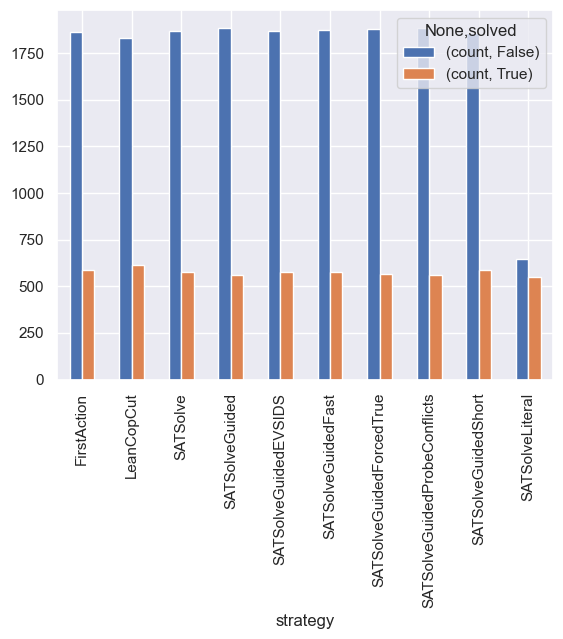

In [16]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

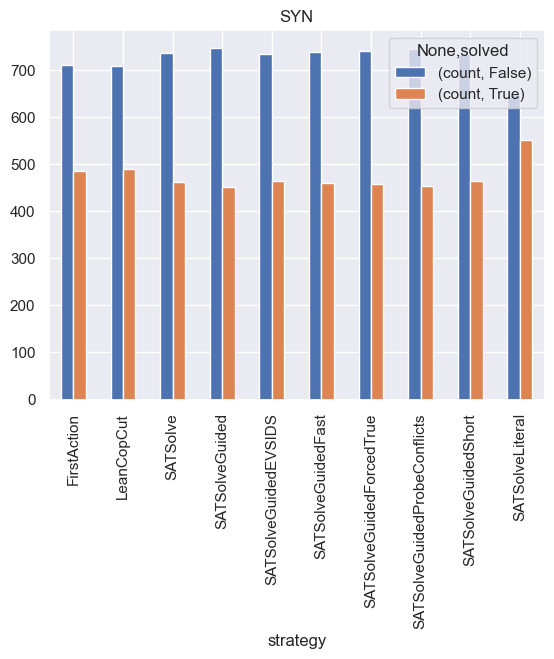

In [17]:
data[data.problem.str[:3] == 'SYN'].groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()
pyplot.title('SYN')
None

<Axes: xlabel='winner', ylabel='loser'>

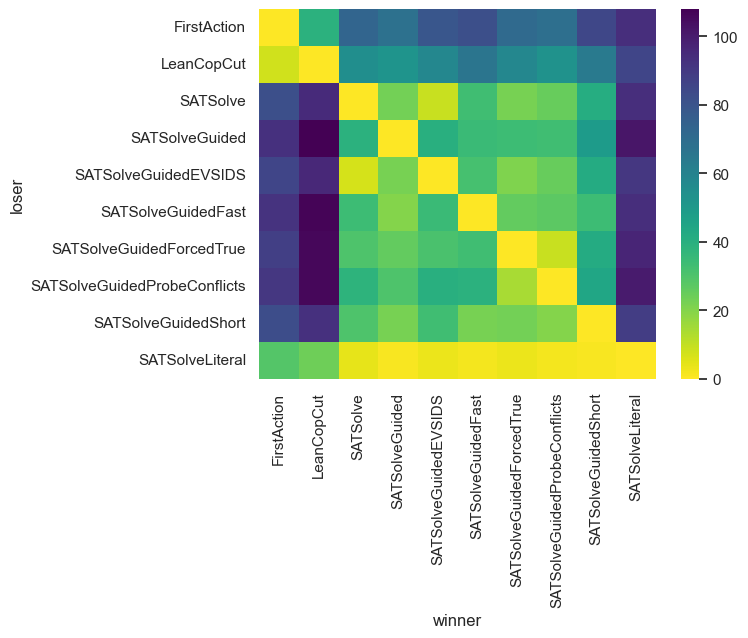

In [18]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [32]:
results[cols].loc[cols.rename('')]

winner,SATSolve,SATSolveGuided,SATSolveGuidedEVSIDS,SATSolveGuidedFast,SATSolveGuidedForcedTrue,SATSolveGuidedProbeConflicts,SATSolveGuidedShort,SATSolveLiteral
,,,,,,,,
SATSolve,0,23,9,33,22,25,41,94
SATSolveGuided,39,0,40,35,34,33,49,102
SATSolveGuidedEVSIDS,7,22,0,32,21,25,42,91
SATSolveGuidedFast,34,20,35,0,26,27,34,94
SATSolveGuidedForcedTrue,30,26,31,33,0,9,42,97
SATSolveGuidedProbeConflicts,38,30,40,39,14,0,44,100
SATSolveGuidedShort,30,22,33,22,23,20,0,89
SATSolveLiteral,4,1,3,2,3,2,1,0


<Axes: xlabel='winner', ylabel='loser'>

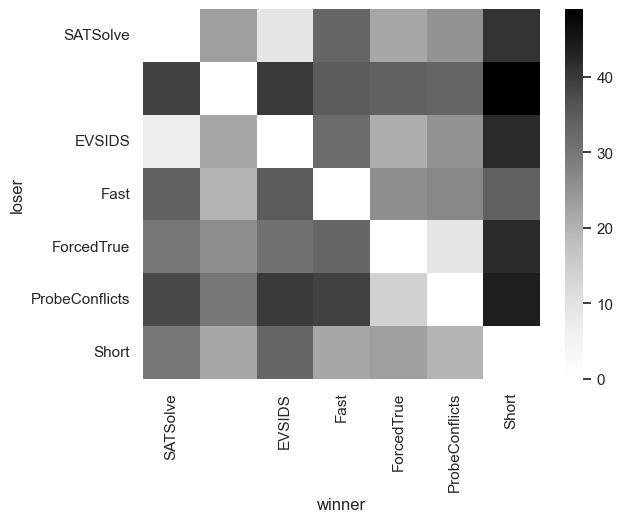

In [47]:
cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
seaborn.heatmap(
    (
        results.
        loc[cols, cols].
        rename_axis(index = 'loser', columns = 'winner').
        rename(index = lambda x: x.removeprefix('SATSolveGuided')).
        rename(columns = lambda x: x.removeprefix('SATSolveGuided'))
    ),
    cmap = 'Grays',
)

In [44]:
results.rename(lambda x: x.removeprefix('SATSolve'))

winner,FirstAction,LeanCopCut,SATSolve,SATSolveGuided,SATSolveGuidedEVSIDS,SATSolveGuidedFast,SATSolveGuidedForcedTrue,SATSolveGuidedProbeConflicts,SATSolveGuidedShort,SATSolveLiteral
loser,,,,,,,,,,
FirstAction,0,39,73,68,79,82,71,69,85,94
LeanCopCut,8,0,55,52,58,66,58,53,64,86
,82,95,0,23,9,33,22,25,41,94
Guided,93,108,39,0,40,35,34,33,49,102
GuidedEVSIDS,86,96,7,22,0,32,21,25,42,91
GuidedFast,92,107,34,20,35,0,26,27,34,94
GuidedForcedTrue,88,106,30,26,31,33,0,9,42,97
GuidedProbeConflicts,91,106,38,30,40,39,14,0,44,100
GuidedShort,83,93,30,22,33,22,23,20,0,89


# Analysis

In [19]:
data['info'].loc[lambda x: ~x.isin(['Theorem', 'Theorem (SAT)'])].iloc[0]

nan